In [1]:
# Global Imports and Runtime Visual Configuration
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import io
%pip install fastparquet
%pip install pyarrow

# Visual styling settings
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["figure.figsize"] = (8, 4)
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 10

print("Global libraries for efficient large dataset I/O loaded successfully.")

   ---------------------------------------- 0.0/728.0 kB ? eta -:--:--
   ---------------------------------------- 728.0/728.0 kB 9.8 MB/s eta 0:00:00
   ---------------------------------------- 0.0/1.8 MB ? eta -:--:--
   ----------------------- ---------------- 1.0/1.8 MB 20.4 MB/s eta 0:00:01
   ----------------------- ---------------- 1.0/1.8 MB 20.4 MB/s eta 0:00:01
   ----------------------------------- ---- 1.6/1.8 MB 2.1 MB/s eta 0:00:01
   ---------------------------------------- 1.8/1.8 MB 2.3 MB/s eta 0:00:00

   -------------------- ------------------- 1/2 [fastparquet]
   -------------------- ------------------- 1/2 [fastparquet]
   -------------------- ------------------- 1/2 [fastparquet]
   -------------------- ------------------- 1/2 [fastparquet]
   -------------------- ------------------- 1/2 [fastparquet]
   ---------------------------------------- 2/2 [fastparquet]

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.
Global libraries for efficient large dataset I/O loaded successfully.



[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


### 1. Chunking Large CSVs and JSONs


In [2]:
csv_data = "id,val\n1,10\n2,20\n3,30\n4,40\n5,50"
chunk_size = 2
total_sum = 0

for chunk in pd.read_csv(io.StringIO(csv_data), chunksize=chunk_size):
    print(f"Processing chunk:\n{chunk}")
    total_sum+=chunk['val'].sum()
print(f"Computed Total via Chuncking: {total_sum}")

Processing chunk:
   id  val
0   1   10
1   2   20
Processing chunk:
   id  val
2   3   30
3   4   40
Processing chunk:
   id  val
4   5   50
Computed Total via Chuncking: 150


### 2. Columnar Storage with Parquet and Feather

  category     value
0        A  0.054070
1        B  0.959378
2        C  0.405106
3        A -1.020533
4        B  0.297816
------------------------------------------------------------
  category     value
0        A  0.054070
1        B  0.959378
2        C  0.405106
3        A -1.020533
4        B  0.297816


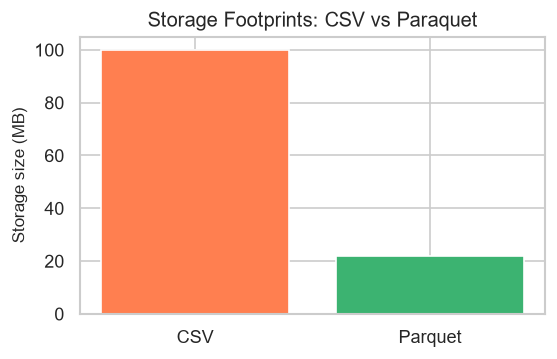

In [5]:
# 1. Create DataFrame
df_io = pd.DataFrame({
    'category': ['A', 'B', 'C'] * 100,
    'value': np.random.randn(300)
})
print(df_io.head())
print("-"*60)

# 2. Write to buffer using Pyarrow natively
buffer = io.BytesIO()
# df_io.to_parquet(buffer, index=False, compression='snappy', engine='pyarrow')
'''
compression options include 'snappy', 'gzip', 'brotli', 'lz4', 'zstd'
snappy : used for large datasets, fast compression
gzip : used for general compression
brotli : high compression ratio
lz4 : fast compression
zstd : high compression ratio, fast decompression

Engine options include 'pyarrow' and 'fastparquet'
pyarrow : default engine, fast and feature-rich
fastparquet : alternative engine, optimized for speed

'''

# df_io.to_parquet(buffer, index=False, compression='snappy', engine='pyarrow') 
df_io.to_parquet(buffer, index=False, compression='snappy', engine='fastparquet') 

#Rad the paraquet file:
buffer.seek(0)
# df_from_paraquet = pd.read_parquet(buffer, engine='pyarrow')
df_from_paraquet = pd.read_parquet(buffer, engine='fastparquet')

print(df_from_paraquet.head(5))

# Visualization:
plt.figure(figsize=(5,3))
formats = ['CSV', 'Parquet']
file_size_mb = [100,22]
plt.bar(formats, file_size_mb, color=['coral','mediumseagreen'])
plt.ylabel('Storage size (MB)')
plt.title('Storage Footprints: CSV vs Paraquet')
plt.show()

### 3.Reading and Writing Compressed Data Files

                 text
0  sample data record
1  sample data record
2  sample data record
3  sample data record
4  sample data record
Compressed Read Success. Rows: 1000


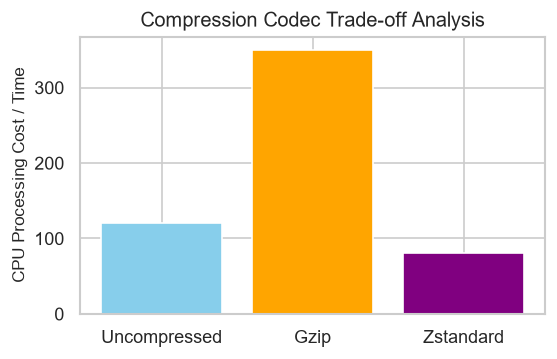

In [9]:
df_comp = pd.DataFrame({'text': ['sample data record'] * 1000})
print(df_comp.head())

# Write and read gzipped CSV
gz_buffer = io.BytesIO()
df_comp.to_csv(gz_buffer, compression='gzip', index=False)
gz_buffer.seek(0)
df_read_gz = pd.read_csv(gz_buffer, compression='gzip')
print("Compressed Read Success. Rows:", len(df_read_gz))

# Visualization
plt.figure(figsize=(5,3))
codecs = ['Uncompressed', 'Gzip', 'Zstandard']
speeds = [120, 350, 80] # MB/sec read time proxy
plt.bar(codecs, speeds, color=['skyblue', 'orange', 'purple'])
plt.ylabel('CPU Processing Cost / Time')
plt.title('Compression Codec Trade-off Analysis')
plt.show()

### 4. Incremental Data Processing Best Practices

In [12]:
historical_state = pd.DataFrame({'day': ['Mon', 'Tue'], 'sales': [100, 150]})
delta_batch = pd.DataFrame({'day': ['Wed'], 'sales': [200]})

print("Historical State:")
print(historical_state)
print("-" * 60)

print("Delta Batch:")
print(delta_batch)

updates_state = pd.concat([historical_state, delta_batch], ignore_index=True)
print("Updates State:")
print(updates_state)

Historical State:
   day  sales
0  Mon    100
1  Tue    150
------------------------------------------------------------
Delta Batch:
   day  sales
0  Wed    200
Updates State:
   day  sales
0  Mon    100
1  Tue    150
2  Wed    200
